# FOLIO results: all models
Read saved JSONL files, calculate metrics with `runner.metrics`, and compare every available model/effort together.

In [1]:
from pathlib import Path
import sys
import warnings

import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# find files
# Search the working folder and its parents for the project containing runner/metrics.py.
framework = next(
    (folder for parent in [Path.cwd(), *Path.cwd().parents]
     for folder in (parent, parent / "myLTRAG" / "FOLIO_framework")
     if (folder / "runner" / "metrics.py").is_file()),
    None,
)
if framework is None:
    raise FileNotFoundError("Open this notebook within the project directory.")
# Let Python find the project imports below; this does not change the working folder.
sys.path.insert(0, str(framework))

# import
from runner.metrics import load_and_calculate_results
from runner.settings import PRICE_TABLE


## Discover inputs
`DATA_ROOT` contains live model directories. Leave `MODELS` and `EFFORTS` as `None` to include all available configurations, or supply lists to filter.

Only named prediction outputs are selected, never `res_*` or temporary files. Multiple files for one model/effort/method are ambiguous and require selection in `FILE_OVERRIDES`. LTRAG uses symbol plus repair usage, not the merged prediction file. Live repair files may be stale; use known matching raw files or `USAGE_OVERRIDES` (symbol only when no repairs occurred).


In [ ]:
import json

DATA_ROOT = framework / "data.nosync" / "folio"
# None includes every model/effort; use lists to select specific ones.
MODELS = None
EFFORTS = None
# Override automatic choices when files are ambiguous or usage needs different sources.
FILE_OVERRIDES = {}  # (model, effort, method): Path(...)
USAGE_OVERRIDES = {}  # (model, effort, method): [Path(...), ...]

# Identify method and effort from filenames; no JSONL contents are read here.
candidates = {}
for directory in sorted(DATA_ROOT.iterdir()):
    if not directory.is_dir() or (MODELS is not None and directory.name not in MODELS):
        continue

    # discover each type of jsonl file
    for path in sorted(directory.glob("test_*.jsonl")):
        if path.stem.endswith("_cot"):
            method = "COT"
            effort = path.stem.rsplit("_", 2)[-2]
        elif path.stem.endswith("_standard"):
            method = "STANDARD"
            effort = path.stem.rsplit("_", 2)[-2]
        elif "_full_errfix_" in path.stem:
            method = "LTRAG"
            effort = path.stem.split("_full_errfix_", 1)[0].rsplit("_", 1)[-1]
        else:
            continue
        if EFFORTS is None or effort in EFFORTS:
            candidates.setdefault((directory.name, effort, method), []).append(path)

# Group the chosen prediction and token-usage files by model, effort, and method.
experiments = {}
for key, paths in candidates.items():
    model, effort, method = key
    if len(paths) > 1 and key not in FILE_OVERRIDES:
        raise ValueError(f"Choose FILE_OVERRIDES[{key!r}] from {paths}")
    prediction = Path(FILE_OVERRIDES.get(key, paths[0]))
    if method == "LTRAG":
        # LTRAG scores final predictions, but counts tokens from symbol and repair calls.
        prefix, repair_tail = prediction.stem.split("_full_errfix_", 1)
        symbol = prediction.with_name(prefix + "_symbol.jsonl")
        repair_model, temperature, examples = repair_tail.rsplit("_", 2)
        repair_prefix = prefix.rsplit("_", 1)[0]
        repair = prediction.with_name(f"{repair_prefix}_errfix_{temperature}_{examples}_{effort}.jsonl")
        usage = [symbol] + ([repair] if repair.is_file() else [])
    else:
        usage = [prediction]
    usage = [Path(path) for path in USAGE_OVERRIDES.get(key, usage)]
    for path in [prediction, *usage]:
        if not path.is_file():
            raise FileNotFoundError(path)
    experiments.setdefault((model, effort), {})[method] = {
        "predictions_file": prediction, "usage_files": usage,
    }

if not experiments:
    raise ValueError("No prediction JSONL files found for these filters.")
print(f"Found {len(experiments)} model/effort configurations across {len({model for model, _ in experiments})} model directories.")
# Report historical summaries without selected raw data; their saved metrics are not loaded.
summary_models = {path.stem for path in (framework / "runs").glob("*.json")}
missing_raw = summary_models - {model for model, _ in experiments}
if missing_raw:
    print("Historical summary exists but no selected raw predictions:", ", ".join(sorted(missing_raw)))


Found 7 model/effort configurations across 4 model directories.
Historical summary exists but no selected raw predictions: gpt-4o-mini


## Calculate and check alignment
Metrics come from JSONL, not saved summary values. Within each model/effort, IDs and gold labels should match across methods. Different sample sizes remain visible; unaligned configurations are excluded from comparison charts.


In [3]:
all_results = {}
records = []
sources = []
for (model, effort), outputs in experiments.items():
    if model not in PRICE_TABLE:
        raise ValueError(f"Add a price for {model} in settings.py.")
    # metrics.py reads the JSONL files and calculates scores, token totals, and estimated costs.
    results = load_and_calculate_results(outputs, model, PRICE_TABLE)
    # Check already-loaded rows: every method must use the same IDs and ground-truth labels.
    gold_sets = []
    for method, result in results.items():
        ids = result["sample_ids"]
        if not ids or None in ids or len(set(ids)) != len(ids) or result["invalid_ground_truth"]:
            raise ValueError(f"Invalid sample IDs or gold labels: {model}/{effort}/{method}")
        gold_sets.append({row["id"]: row["label"] for row in result["rows"]})
    aligned = all(gold == gold_sets[0] for gold in gold_sets)
    if not aligned:
        warnings.warn(f"Unmatched samples: {model}/{effort}. Excluded from charts.")
    for method, result in results.items():
        key = (model, effort, method)
        all_results[key] = result
        usage_present = result["usage_complete"]
        if not usage_present:
            warnings.warn(f"Missing usage for {model}/{effort}/{method}; cost is incomplete.")
        # Collect calculated values into one table row per method.
        records.append({
            "Model": model, "Effort": effort, "Method": method,
            "Samples": result["total"], "Aligned": aligned,
            "Accuracy": result["accuracy"],
            "Precision (macro)": result["macro_average"]["precision"],
            "Recall (macro)": result["macro_average"]["recall"],
            "F1 (macro)": result["macro_average"]["f1"],
            "Errors": result["errors"],
            "Unknown precision": result["unknown_precision"],
            "Unknown recall": result["unknown_recall"],
            "True/False accuracy": result["definite_answer_accuracy"],
            "True/False rate": result["definite_answer_rate"],
            **result["tokens"],
            "Cost USD": result["estimated_cost_usd"],
            "USD / sample": result["estimated_cost_usd"] / result["total"],
            "Usage present": usage_present,
        })
        sources.append({"Model": model, "Effort": effort, "Method": method,
                        "Predictions": str(outputs[method]["predictions_file"]),
                        "Usage files": ", ".join(str(path) for path in outputs[method]["usage_files"])})

# Build the results table and order efforts from lower to higher reasoning effort.
frame = pd.DataFrame(records).set_index(["Model", "Effort", "Method"])
effort_order = ["na", "none", "minimal", "low", "medium", "high", "xhigh"]
ordered = sorted(frame.index, key=lambda key: (
    key[0], effort_order.index(key[1]) if key[1] in effort_order else len(effort_order),
    ["COT", "STANDARD", "LTRAG"].index(key[2]),
))
frame = frame.reindex(pd.MultiIndex.from_tuples(ordered, names=frame.index.names))
print("Source labels are not verified model identities; sample alignment does not establish shared run provenance.")


Source labels are not verified model identities; sample alignment does not establish shared run provenance.


## Classification Metrics
Precision, recall, and F1 are macro averages over True, False, and Unknown. Errors count as incorrect. Each row includes its sample count.


In [4]:
score_columns = ["Accuracy", "Precision (macro)", "Recall (macro)", "F1 (macro)"]
display(frame[["Samples", *score_columns, "Errors", "Aligned"]].style.format(
    {**{name: "{:.2%}" for name in score_columns}, "Samples": "{:.0f}", "Errors": "{:.0f}"}, na_rep="—",
))


## Unknown and True/False behavior
True/False accuracy is conditional on predicting True or False, not on the gold label. Read it alongside the prediction rate. Undefined ratios display as `—`.


In [5]:
behavior_columns = ["Unknown precision", "Unknown recall", "True/False accuracy", "True/False rate"]
display(frame[["Samples", *behavior_columns]].style.format(
    {**{name: "{:.2%}" for name in behavior_columns}, "Samples": "{:.0f}"}, na_rep="—",
))


## Tokens and estimated costs
Output includes reasoning tokens. Missing historical extractor usage cannot be recovered from these counts. Compare per-sample costs when sample counts differ; model labels and pricing still need provenance verification.


In [6]:
token_columns = ["input", "cached_input", "output", "reasoning"]
display(frame[["Samples", *token_columns, "Cost USD", "USD / sample", "Usage present"]].style.format(
    {**{name: "{:,.0f}" for name in ["Samples", *token_columns]},
     "Cost USD": "${:.4f}", "USD / sample": "${:.6f}"}, na_rep="—",
))


## Compare methods across models and efforts
Each x-axis group includes its sample count. Groups are separate experiments, not a pooled score.


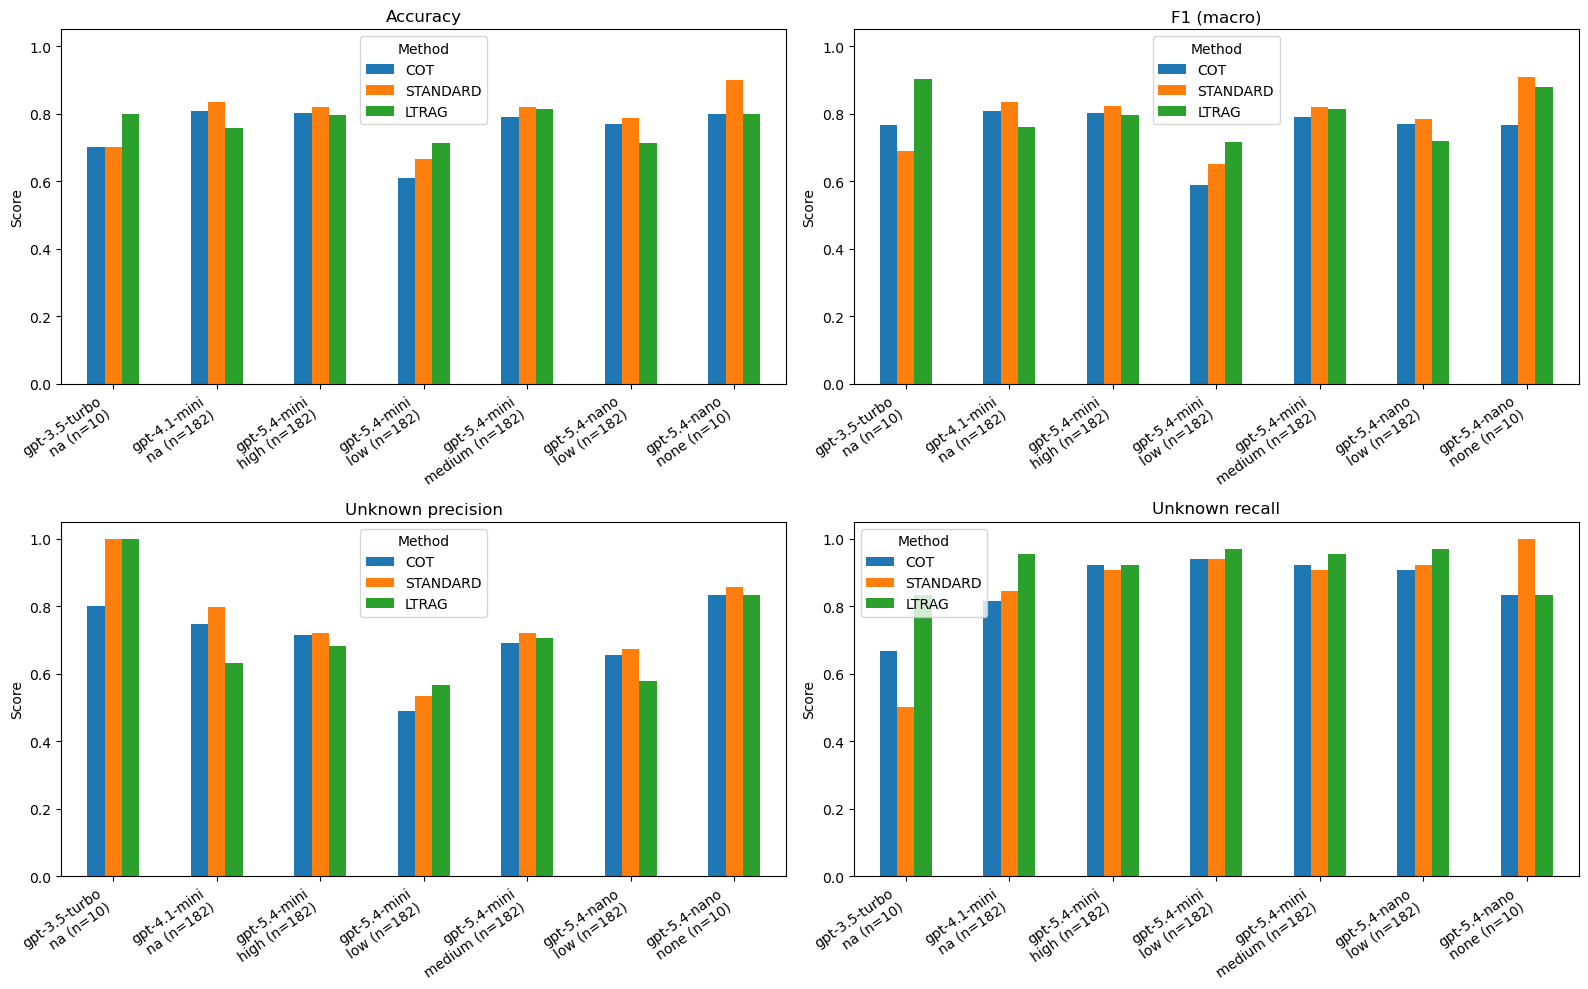

In [7]:
# Compare methods only where their sample IDs and ground-truth labels match.
chart_rows = frame[frame["Aligned"]].reset_index()
chart_rows["Configuration"] = chart_rows.apply(
    lambda row: f"{row['Model']}\n{row['Effort']} (n={row['Samples']})", axis=1,
)
if not chart_rows.empty:
    fig, axes = plt.subplots(2, 2, figsize=(16, 10))
    for ax, metric in zip(axes.flat, ["Accuracy", "F1 (macro)", "Unknown precision", "Unknown recall"]):
        # Arrange methods as separate bar series for each model/effort configuration.
        table = chart_rows.pivot(index="Configuration", columns="Method", values=metric)
        table = table.reindex(columns=[name for name in ["COT", "STANDARD", "LTRAG"] if name in table])
        table.plot.bar(ax=ax, ylim=(0, 1.05), rot=35)
        ax.set(title=metric, ylabel="Score", xlabel="")
        plt.setp(ax.get_xticklabels(), ha="right")
    plt.tight_layout()
    plt.show()


## Confusion matrices — all available configurations
Rows are gold labels and columns are predictions. Error remains distinct from Unknown in reporting. The inherited solver behavior is unchanged.


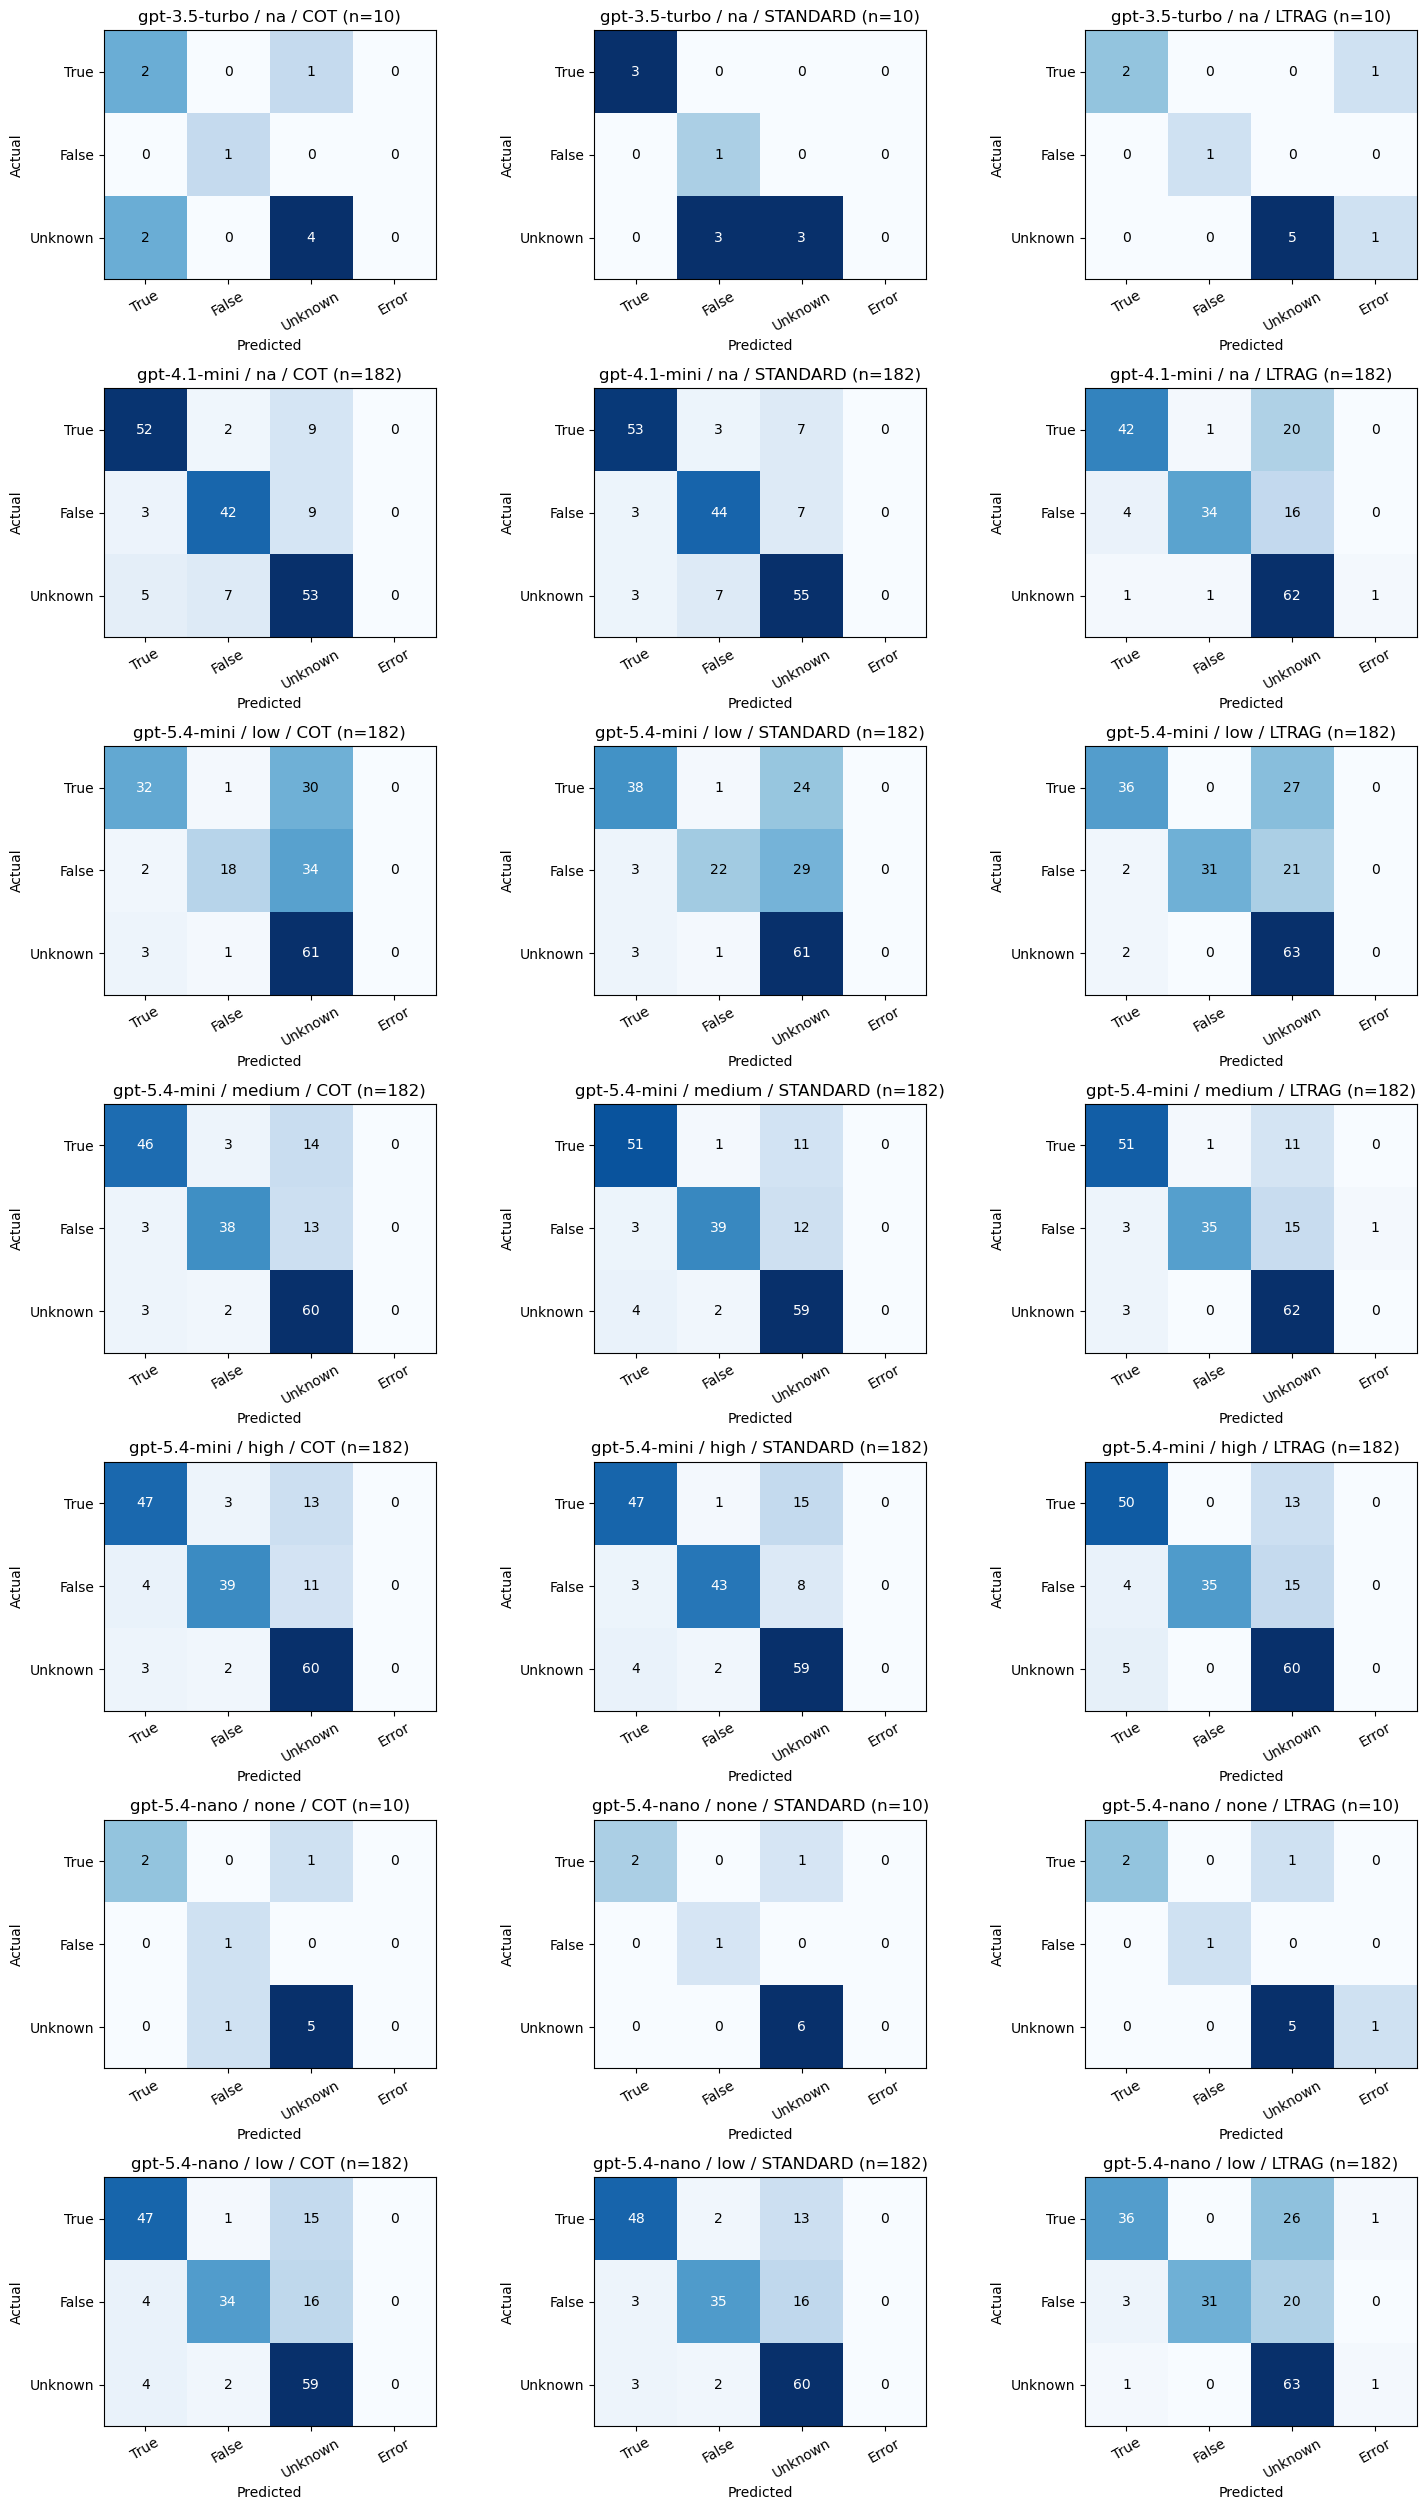

In [8]:
# One chart row per model/effort; confusion matrices show actual versus predicted labels.
configurations = list(dict.fromkeys((model, effort) for model, effort, _ in frame.index))
fig, axes = plt.subplots(len(configurations), 3, figsize=(15, 3.6 * len(configurations)), squeeze=False)
for row_index, (model, effort) in enumerate(configurations):
    for col_index, method in enumerate(["COT", "STANDARD", "LTRAG"]):
        ax = axes[row_index, col_index]
        result = all_results.get((model, effort, method))
        if result is None:
            ax.set_visible(False)
            continue
        matrix = pd.DataFrame.from_dict(result["confusion_matrix"], orient="index")
        maximum = max(matrix.to_numpy().max(), 1)
        ax.imshow(matrix.values, cmap="Blues", vmin=0, vmax=maximum)
        ax.set_xticks(range(len(matrix.columns)), matrix.columns, rotation=30)
        ax.set_yticks(range(len(matrix.index)), matrix.index)
        ax.set(title=f"{model} / {effort} / {method} (n={result['total']})", xlabel="Predicted", ylabel="Actual")
        for row in range(len(matrix.index)):
            for col in range(len(matrix.columns)):
                count = matrix.iloc[row, col]
                ax.text(col, row, str(count), ha="center", va="center",
                        color="white" if count > maximum / 2 else "black")
plt.tight_layout()
plt.show()


## Source files
Use this table to trace each displayed result to its prediction and usage files.


In [9]:
display(pd.DataFrame(sources).set_index(["Model", "Effort", "Method"]))


Predictions  \
Model         Effort Method                                                        
gpt-3.5-turbo na     STANDARD  /Users/ramialhabash/Library/Mobile Documents/c...   
                     LTRAG     /Users/ramialhabash/Library/Mobile Documents/c...   
                     COT       /Users/ramialhabash/Library/Mobile Documents/c...   
gpt-4.1-mini  na     STANDARD  /Users/ramialhabash/Library/Mobile Documents/c...   
                     LTRAG     /Users/ramialhabash/Library/Mobile Documents/c...   
                     COT       /Users/ramialhabash/Library/Mobile Documents/c...   
gpt-5.4-mini  high   STANDARD  /Users/ramialhabash/Library/Mobile Documents/c...   
                     LTRAG     /Users/ramialhabash/Library/Mobile Documents/c...   
                     COT       /Users/ramialhabash/Library/Mobile Documents/c...   
              low    STANDARD  /Users/ramialhabash/Library/Mobile Documents/c...   
                     LTRAG     /Users/ramialhabash/Library/Mobile Documents/c...   
                     COT       /Users/ramialhabash/Library/Mobile Documents/c...   
              medium STANDARD  /Users/ramialhabash/Library/Mobile Documents/c...   
                     LTRAG     /Users/ramialhabash/Library/Mobile Documents/c...   
                     COT       /Users/ramialhabash/Library/Mobile Documents/c...   
gpt-5.4-nano  low    STANDARD  /Users/ramialhabash/Library/Mobile Documents/c...   
                     LTRAG     /Users/ramialhabash/Library/Mobile Documents/c...   
                     COT       /Users/ramialhabash/Library/Mobile Documents/c...   
              none   STANDARD  /Users/ramialhabash/Library/Mobile Documents/c...   
                     LTRAG     /Users/ramialhabash/Library/Mobile Documents/c...   
                     COT       /Users/ramialhabash/Library/Mobile Documents/c...   

                                                                     Usage files  
Model         Effort Method                                                       
gpt-3.5-turbo na     STANDARD  /Users/ramialhabash/Library/Mobile Documents/c...  
                     LTRAG     /Users/ramialhabash/Library/Mobile Documents/c...  
                     COT       /Users/ramialhabash/Library/Mobile Documents/c...  
gpt-4.1-mini  na     STANDARD  /Users/ramialhabash/Library/Mobile Documents/c...  
                     LTRAG     /Users/ramialhabash/Library/Mobile Documents/c...  
                     COT       /Users/ramialhabash/Library/Mobile Documents/c...  
gpt-5.4-mini  high   STANDARD  /Users/ramialhabash/Library/Mobile Documents/c...  
                     LTRAG     /Users/ramialhabash/Library/Mobile Documents/c...  
                     COT       /Users/ramialhabash/Library/Mobile Documents/c...  
              low    STANDARD  /Users/ramialhabash/Library/Mobile Documents/c...  
                     LTRAG     /Users/ramialhabash/Library/Mobile Documents/c...  
                     COT       /Users/ramialhabash/Library/Mobile Documents/c...  
              medium STANDARD  /Users/ramialhabash/Library/Mobile Documents/c...  
                     LTRAG     /Users/ramialhabash/Library/Mobile Documents/c...  
                     COT       /Users/ramialhabash/Library/Mobile Documents/c...  
gpt-5.4-nano  low    STANDARD  /Users/ramialhabash/Library/Mobile Documents/c...  
                     LTRAG     /Users/ramialhabash/Library/Mobile Documents/c...  
                     COT       /Users/ramialhabash/Library/Mobile Documents/c...  
              none   STANDARD  /Users/ramialhabash/Library/Mobile Documents/c...  
                     LTRAG     /Users/ramialhabash/Library/Mobile Documents/c...  
                     COT       /Users/ramialhabash/Library/Mobile Documents/c...